In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Project folders
RAW_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")

# Load cleaned datasets
matches = pd.read_csv(PROCESSED_DIR / "matches_cleaned.csv")
deliveries = pd.read_csv(PROCESSED_DIR / "deliveries_cleaned.csv")
points_table = pd.read_csv(PROCESSED_DIR / "points_table_cleaned.csv")

print("All datasets loaded successfully!")


All datasets loaded successfully!


In [ ]:
print("Matches:", matches.shape)
print("Deliveries:", deliveries.shape)
print("Points Table:", points_table.shape)

Matches: (48, 18)
Deliveries: (26118, 22)
Points Table: (10, 11)


In [ ]:

print("Dataset columns:")
print(matches.columns.tolist())

print("\nFirst 5 matches:")
display(matches.head())

print("\nMatch winners:")
display(matches["winner"].value_counts())

Dataset columns:
['season', 'team1', 'team2', 'date', 'match_number', 'venue', 'city', 'toss_winner', 'toss_decision', 'player_of_match', 'umpire1', 'umpire2', 'reserve_umpire', 'match_referee', 'winner', 'winner_runs', 'winner_wickets', 'match_type']

First 5 matches:


,season,team1,team2,date,match_number,venue,city,toss_winner,toss_decision,player_of_match,umpire1,umpire2,reserve_umpire,match_referee,winner,winner_runs,winner_wickets,match_type
0,2023/24,England,New Zealand,2023-10-05,1,Narendra Modi Stadium,Ahmedabad,New Zealand,field,R Ravindra,HDPK Dharmasena,Nitin Menon,Sharfuddoula,J Srinath,New Zealand,NaN,9.0,Group
1,2023/24,Pakistan,Netherlands,2023-10-06,2,Rajiv Gandhi International Stadium,Hyderabad,Netherlands,field,Saud Shakeel,AT Holdstock,CM Brown,PR Reiffel,JJ Crowe,Pakistan,81.0,NaN,Group
2,2023/24,Afghanistan,Bangladesh,2023-10-07,3,Himachal Pradesh Cricket Association Stadium,Dharamsala,Bangladesh,field,Mehedi Hasan Miraz,JS Wilson,HDPK Dharmasena,M Erasmus,AJ Pycroft,Bangladesh,NaN,6.0,Group
3,2023/24,South Africa,Sri Lanka,2023-10-07,4,Arun Jaitley Stadium,Delhi,Sri Lanka,field,AK Markram,RK Illingworth,Sharfuddoula,AG Wharf,J Srinath,South Africa,102.0,NaN,Group
4,2023/24,Australia,India,2023-10-08,5,MA Chidambaram Stadium,Chennai,Australia,bat,KL Rahul,CB Gaffaney,RA Kettleborough,AT Holdstock,RB Richardson,India,NaN,6.0,Group



Match winners:


winner
India           10
Australia        9
South Africa     7
New Zealand      5
Pakistan         4
Afghanistan      4
England          3
Bangladesh       2
Netherlands      2
Sri Lanka        2
Name: count, dtype: int64

In [ ]:
# Q1. How many matches were played in the tournament?
total_matches_played = len(matches)
print("Total matches played:", total_matches_played)


Total matches played: 48


,Team,Total_Wins
0,India,10
1,Australia,9
2,South Africa,7
3,New Zealand,5
4,Pakistan,4
5,Afghanistan,4
6,England,3
7,Bangladesh,2
8,Netherlands,2
9,Sri Lanka,2


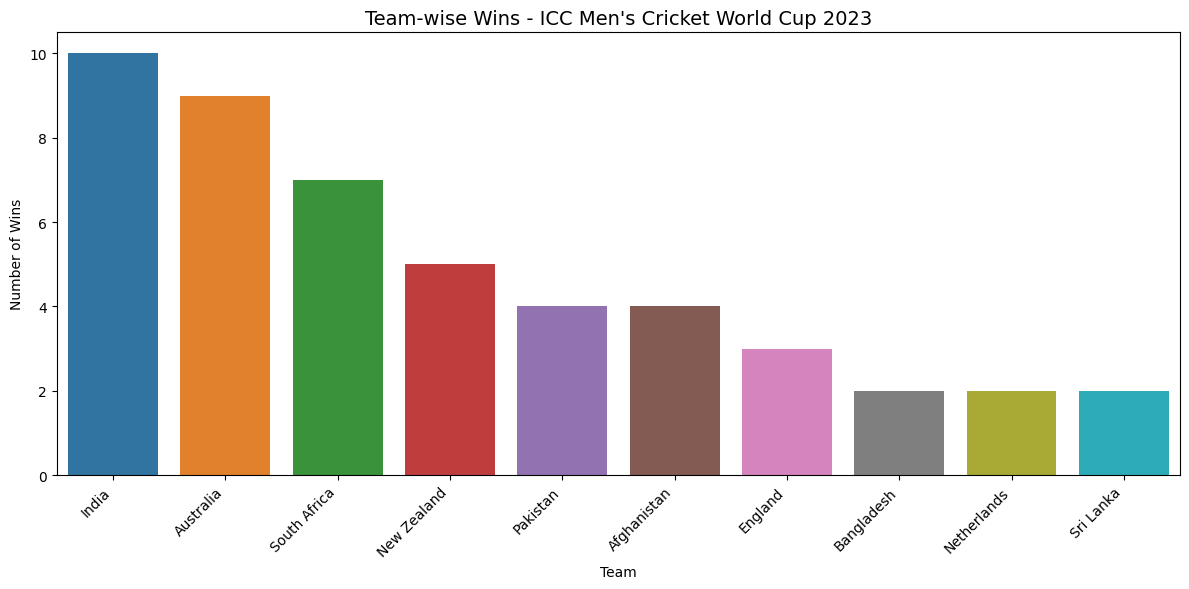

In [ ]:
# Q2. Which teams recorded the highest number of wins in the ICC Men's Cricket World Cup 2023?

team_wins = (
    matches["winner"]
    .dropna()
    .value_counts()
    .reset_index()
)

team_wins.columns = ["Team", "Total_Wins"]

team_wins = team_wins.sort_values(
    by="Total_Wins",
    ascending=False
).reset_index(drop=True)

display(team_wins)


plt.figure(figsize=(12, 6))

sns.barplot(
    data=team_wins,
    x="Team",
    y="Total_Wins",
    hue="Team",
    legend=False
    
)

plt.title(
    "Team-wise Wins - ICC Men's Cricket World Cup 2023",
    fontsize=14
)
plt.xlabel("Team")
plt.ylabel("Number of Wins")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

,Toss_Decision,Count,Percentage
0,field,26,54.17
1,bat,22,45.83


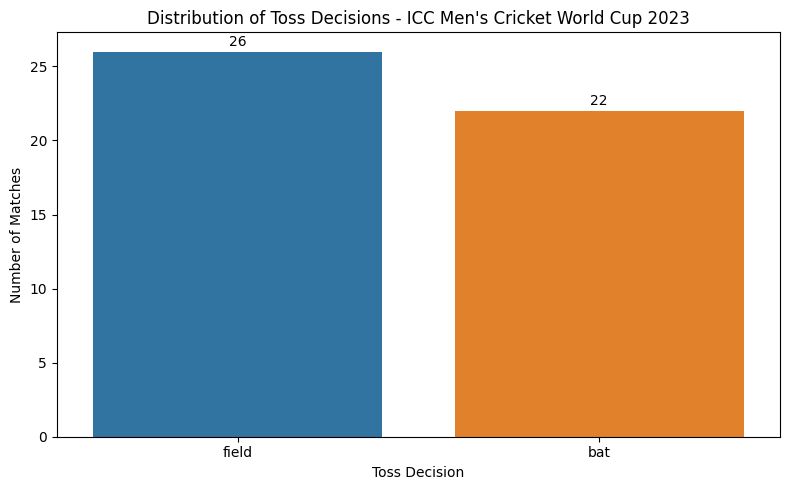

In [ ]:
# Q2. What was the distribution of toss decisions between batting first and fielding first?

toss_distribution  = (
    matches["toss_decision"]
    .dropna()
    .value_counts()
    .reset_index()
)
toss_distribution.columns = ["Toss_Decision", "Count"]

# calculate percentage 

total_decisions = toss_distribution["Count"].sum()

toss_distribution["Percentage"] = (
    toss_distribution["Count"] / total_decisions * 100
).round(2)

display(toss_distribution)

plt.figure(figsize=(8,5))

ax = sns.barplot(
    data=toss_distribution,
    x="Toss_Decision",
    y="Count",
    hue="Toss_Decision",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=2)
    
plt.title(
    "Distribution of Toss Decisions - ICC Men's Cricket World Cup 2023"
)
plt.xlabel("Toss Decision")
plt.ylabel("Number of Matches")
plt.tight_layout()
plt.show()

,toss_winner,winner,toss_and_match_winner
0,New Zealand,New Zealand,True
1,Netherlands,Pakistan,False
2,Bangladesh,Bangladesh,True
3,Sri Lanka,South Africa,False
4,Australia,India,False
5,Netherlands,New Zealand,False
6,Bangladesh,England,False
7,Sri Lanka,Pakistan,False
8,Afghanistan,India,False
9,Australia,South Africa,False


Toss-winning team also won the match: 19
Toss-winning team lost the match: 29
Total valid matches: 48

Toss winner also won: 39.58%
Toss winner lost: 60.42%


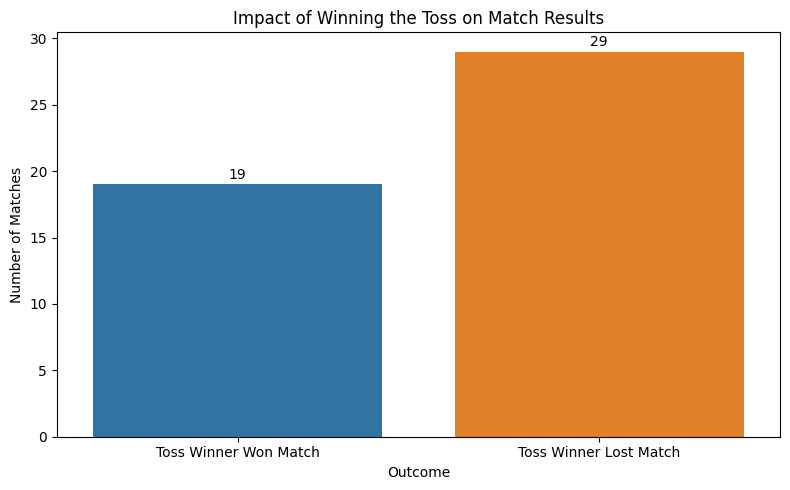

In [ ]:
# Q3. How often did the toss-winning team also win the match? 

# Compare toss winner and match winner
matches["toss_and_match_winner"] = (
    matches["toss_winner"] == matches["winner"]
)

display(
    matches[
        ["toss_winner", "winner", "toss_and_match_winner"]
    ].head(10)
)

# calculate the results
valid_matches = matches.dropna(
    subset=["toss_winner", "winner"]
).copy()

toss_won_match = (
    valid_matches["toss_winner"] == valid_matches["winner"]
).sum()

toss_lost_match = len(valid_matches) - toss_won_match

print("Toss-winning team also won the match:", toss_won_match)
print("Toss-winning team lost the match:", toss_lost_match)
print("Total valid matches:", len(valid_matches))

# Calculate percentage

total_matches = len(valid_matches)

win_percentage = round(
    (toss_won_match / total_matches) * 100, 2
)

loss_percentage = round(
    (toss_lost_match / total_matches) * 100, 2
)

print()
print(f"Toss winner also won: {win_percentage}%")
print(f"Toss winner lost: {loss_percentage}%")

result_df = pd.DataFrame({
    "Result": ["Toss Winner Won Match", "Toss Winner Lost Match"],
    "Matches": [toss_won_match, toss_lost_match]
})

plt.figure(figsize=(8,5))

ax = sns.barplot(
    data=result_df,
    x="Result",
    y="Matches",
    hue="Result",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=2)
    
plt.title("Impact of Winning the Toss on Match Results")
plt.xlabel("Outcome")
plt.ylabel("Number of Matches")
plt.tight_layout()
plt.show()

,Venue,Total_Matches
0,Narendra Modi Stadium,5
1,Himachal Pradesh Cricket Association Stadium,5
2,Maharashtra Cricket Association Stadium,5
3,Arun Jaitley Stadium,5
4,MA Chidambaram Stadium,5
5,Bharat Ratna Shri Atal Bihari Vajpayee Ekana C...,5
6,Wankhede Stadium,5
7,M Chinnaswamy Stadium,5
8,Eden Gardens,5
9,Rajiv Gandhi International Stadium,3


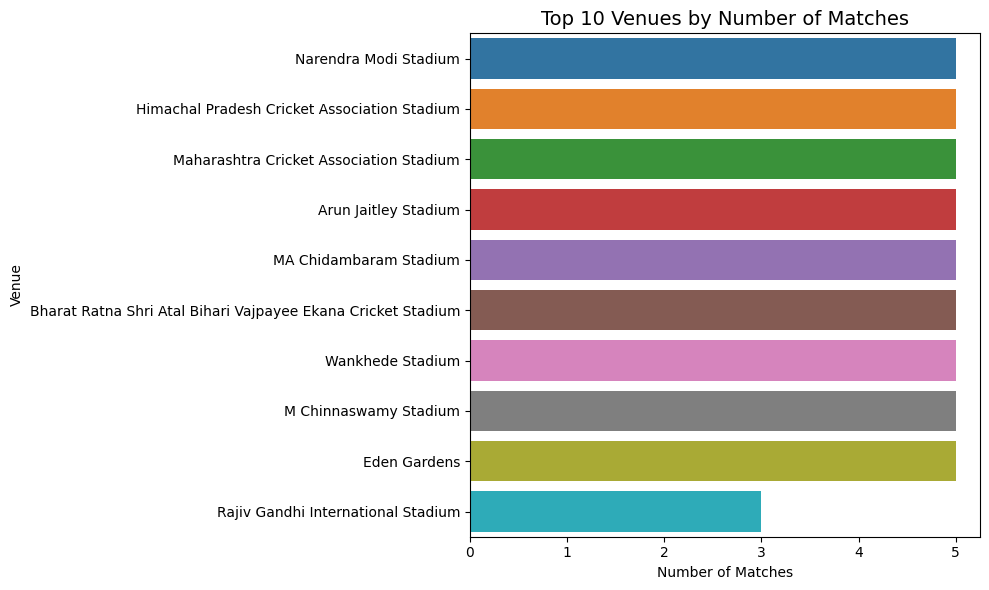

In [ ]:
# Q4. Which venues hosted the highest number of matches during the tournament?

venue_matches = (
    matches["venue"]
    .value_counts()
    .reset_index()
)
venue_matches.columns = ["Venue", "Total_Matches"]

venue_matches = venue_matches.sort_values(
    by="Total_Matches", ascending=False
)

display(venue_matches)

# select top 10 venues
top_10_venues = venue_matches.head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    data=top_10_venues,
    x="Total_Matches",
    y="Venue",
    hue="Venue",
    legend=False
)

plt.title(
    "Top 10 Venues by Number of Matches",
    fontsize=14
)
plt.xlabel("Number of Matches")
plt.ylabel("Venue")

plt.tight_layout()
plt.show()

Cities hosting the highest number of matches:


,City,Total_Matches
0,Ahmedabad,5
1,Dharamsala,5
2,Pune,5
3,Delhi,5
4,Chennai,5
5,Lucknow,5
6,Mumbai,5
7,Bengaluru,5
8,Kolkata,5


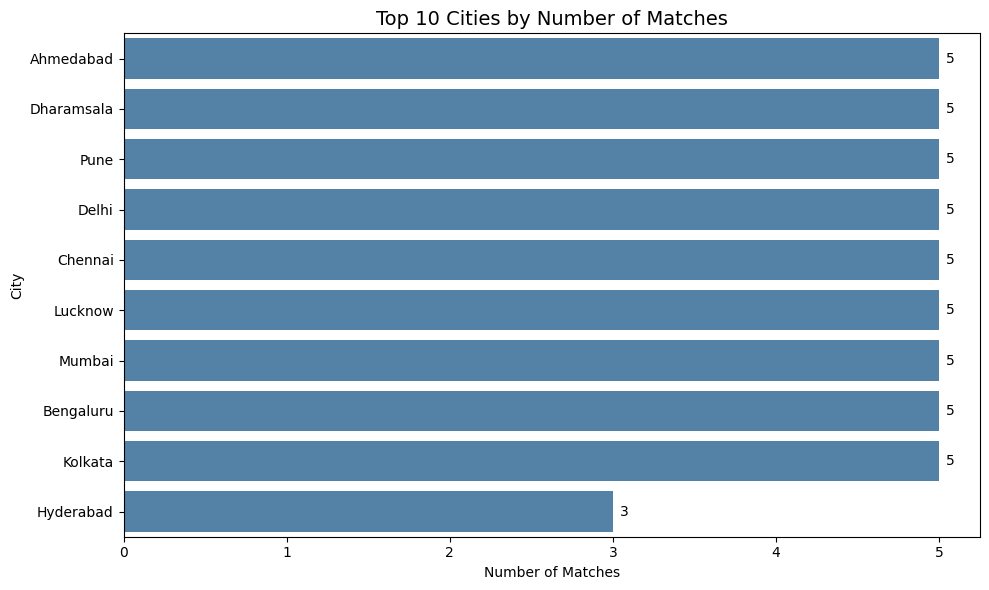

In [ ]:
# Q5. Which cities hosted the highest number of matches?
city_matches = (
    matches["city"].value_counts().reset_index()
)
#rename columns
city_matches.columns = ["City", "Total_Matches"]

city_matches = city_matches.sort_values(
    by="Total_Matches", ascending=False
).reset_index(drop=True)


max_matches = city_matches["Total_Matches"].max()

top_cities = city_matches[
    city_matches["Total_Matches"] == max_matches
]

print("Cities hosting the highest number of matches:")
display(top_cities)


top_10_cities = city_matches.head(10)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=top_10_cities,
    x="Total_Matches",
    y="City",
    color="steelblue"
)

# Add data labels
ax.bar_label(ax.containers[0], padding=5, fontsize=10)

plt.title("Top 10 Cities by Number of Matches", fontsize=14)
plt.xlabel("Number of Matches")
plt.ylabel("City")

plt.tight_layout()
plt.show()

Largest victory by runs:


,winner,venue,winner_runs
23,Australia,Arun Jaitley Stadium,309.0


Largest victory by wickets:


,winner,venue,winner_wickets
0,New Zealand,Narendra Modi Stadium,9.0


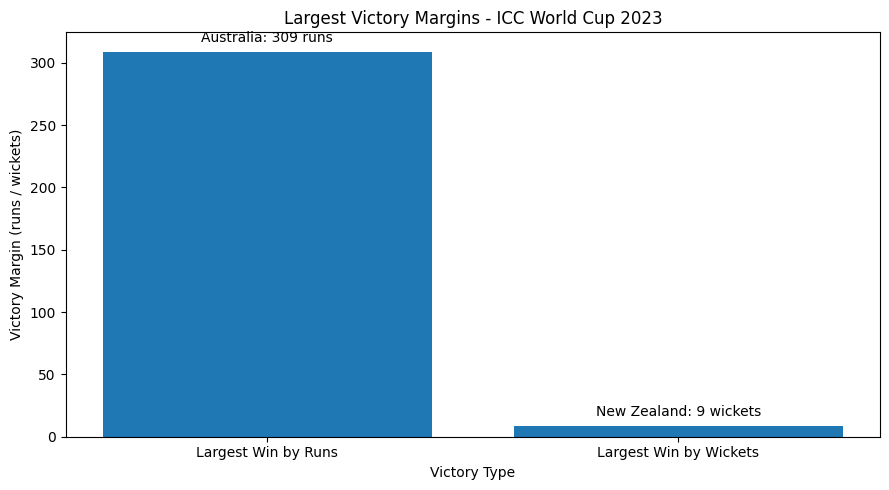

In [ ]:
# Q6. Which teams recorded the largest victory margins by runs and by wickets?

# Convert margins to numeric
matches["winner_runs"] = pd.to_numeric(
    matches["winner_runs"], errors="coerce"
)
matches["winner_wickets"] = pd.to_numeric(
    matches["winner_wickets"], errors="coerce"
)

# Largest victory by runs
largest_run_win = (
    matches.dropna(subset=["winner_runs"])
    .sort_values("winner_runs", ascending=False)
    .head(1)
)

# Largest victory by wickets
largest_wicket_win = (
    matches.dropna(subset=["winner_wickets"])
    .sort_values("winner_wickets", ascending=False)
    .head(1)
)

# Display results
print("Largest victory by runs:")
display(largest_run_win[["winner", "venue", "winner_runs"]])

print("Largest victory by wickets:")
display(largest_wicket_win[["winner", "venue", "winner_wickets"]])

# Prepare data for one chart
categories = ["Largest Win by Runs", "Largest Win by Wickets"]

values = [
    largest_run_win["winner_runs"].iloc[0],
    largest_wicket_win["winner_wickets"].iloc[0]
]

labels = [
    f'{largest_run_win["winner"].iloc[0]}: {values[0]:.0f} runs',
    f'{largest_wicket_win["winner"].iloc[0]}: {values[1]:.0f} wickets'
]

# Plot both columns in one chart
plt.figure(figsize=(9, 5))

bars = plt.bar(categories, values)

plt.bar_label(bars, labels=labels, padding=5)
plt.title("Largest Victory Margins - ICC World Cup 2023")
plt.ylabel("Victory Margin (runs / wickets)")
plt.xlabel("Victory Type")
plt.tight_layout()
plt.show()

,Player,Awards
0,Mohammed Shami,3
1,TM Head,3
2,A Zampa,2
3,RG Sharma,2
4,V Kohli,2
5,HE van der Dussen,2
6,Fakhar Zaman,2
7,GJ Maxwell,2
8,Q de Kock,2
9,R Ravindra,1


Player(s) with the most Player of the Match awards:


,Player,Awards
0,Mohammed Shami,3
1,TM Head,3


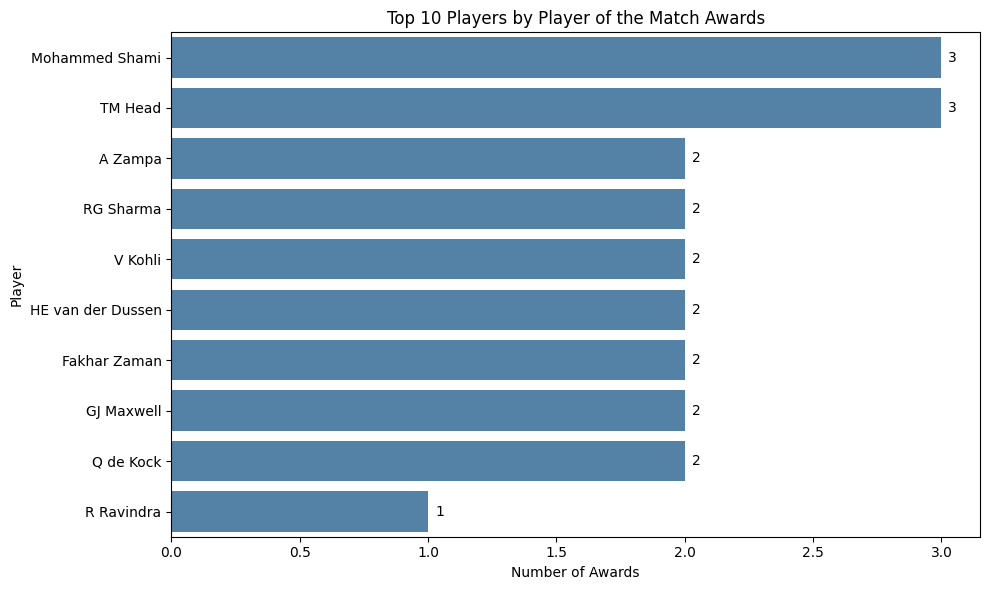

In [ ]:
# Which players received the most Player of the Match awards?

# Count Player of the Match awards
player_awards = (
    matches["player_of_match"]
    .dropna()
    .value_counts()
    .reset_index().head(10)
)

player_awards.columns = ["Player", "Awards"]

# Sort from highest to lowest
player_awards = player_awards.sort_values(
    by="Awards",
    ascending=False
).reset_index(drop=True)

# Display all players
display(player_awards)

# Find player(s) with the most awards
max_awards = player_awards["Awards"].max()

top_players = player_awards[
    player_awards["Awards"] == max_awards
]

print("Player(s) with the most Player of the Match awards:")
display(top_players)



# Select top 10 players
top_10_players = player_awards.head(10)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=top_10_players,
    x="Awards",
    y="Player",
    color="steelblue"
)

# Add data labels
ax.bar_label(ax.containers[0], padding=5, fontsize=10)

plt.title("Top 10 Players by Player of the Match Awards")
plt.xlabel("Number of Awards")
plt.ylabel("Player")

plt.tight_layout()
plt.show()